# 01 - Causal Framing: Loyalty Program Project

**Goal of this notebook:** frame the causal question, work through potential outcomes by hand, build and defend a DAG, and reason about backdoor paths.

**Causal question:**
> Among customers of a retail store, does enrollment in a loyalty program cause an increase in spending over the following 12 months?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from loyalty.dag import build_dag, draw_reference_dag, backdoor_paths

rng = np.random.default_rng(42)  # reuse this one generator throughout

---
# Part A: Potential outcomes by hand

## The setup
### Potential outcomes
- $X$ = loyalty program signup (treatment)
  - $X = 1$: customer signs up
  - $X = 0$: customer does not sign up
- $Y$ = customer spending (outcome)
- $Y_1$ = spending if the customer signs up
- $Y_0$ = spending if the customer does not sign up

---

### The fundamental problem of causal inference:
*We cannot observe both potential outcomes for the same unit at the same time.*

In our experiment, if a customer does **not** sign up for the loyalty program, we observe $Y_i(0)$, but we cannot observe $Y_i(1)$, the **counterfactual** — how much that customer would have spent if they had signed up.

---

### Average Treatment Effect (ATE)

The **ATE** measures the average effect of signing up for the loyalty program on spending across **all customers**.

$$
ATE = E[Y_1 - Y_0]
$$

In this experiment:

> On average, how much does signing up for the loyalty program change customer spending?

---

### Average Treatment Effect on the Treated (ATT)

The **ATT** measures the average effect of the loyalty program **among customers who actually signed up**.

$$
ATT = E[Y_1 - Y_0 \mid X = 1]
$$

In this experiment:

> Among customers who signed up for the loyalty program, how much did the program change their spending?

The key challenge is that we observe $Y_1$ for these customers, but we do not observe their counterfactual $Y_0$.

---

### Average Treatment Effect on the Untreated (ATU)

The **ATU** measures the average effect of the loyalty program **among customers who did not sign up**.

$$
ATU = E[Y_1 - Y_0 \mid X = 0]
$$

In this experiment:

> Among customers who did not sign up for the loyalty program, how much would their spending have changed if they had signed up?

Here, we observe $Y_0$ for these customers, but we do not observe their counterfactual $Y_1$.

---

### Relationship Between ATE, ATT, and ATU

The ATE can be expressed as a weighted average of the ATT and ATU:

$$
ATE = P(X=1)ATT + P(X=0)ATU
$$

Therefore:

- **ATE** → effect for **everyone**
- **ATT** → effect for those who **signed up**
- **ATU** → effect for those who **did not sign up**

---

Before we get deep into the weeds with our population, let’s start with a randomly generated population representing what our outcome data *might* look like. In this example, I am constructing a dataset where enrolling (y_1) in the loyalty program always increases spending.

In [2]:
rng = np.random.default_rng(7)

y0 = np.array([120, 340, 80, 560, 210, 95, 430, 150, 275, 610], dtype=float)  # spend if NOT enrolled
gap = np.array([15, 40, 10, 55, 25, 12, 30, 20, 35, 45], dtype=float)         # differs by customer
y1 = y0 + gap                                                                  # spend if enrolled

df = pd.DataFrame({"customer_id": np.arange(1, 11), "y0": y0, "y1": y1})


In [3]:
df

,customer_id,y0,y1
0,1,120.0,135.0
1,2,340.0,380.0
2,3,80.0,90.0
3,4,560.0,615.0
4,5,210.0,235.0
5,6,95.0,107.0
6,7,430.0,460.0
7,8,150.0,170.0
8,9,275.0,310.0
9,10,610.0,655.0


## Self-selection

Now that we have generated a Y0 and Y1 for each observation, lets create some logic for determining who acutally receieved the treatment (loyalty program sign up)

**Assignment rule.** Enrollment (`d`) is not random. Each customer's probability of enrolling
increases with their baseline spend (`y0`), using a logistic function of standardized `y0`.
Higher-spending customers are therefore more likely, but never certain, to join. This keeps
the overlap assumption intact: every customer has some chance of landing in either group.

**Why this rule.** In the project DAG, factors such as income and deal-seeking behavior drive
both enrollment and spending. In this toy example, baseline spend serves as a single stand-in
for those confounders. Customers select on their baseline level, not on how much they would
gain, which isolates selection bias from any effect-based selection.

**Observed outcome.** Each customer reveals only the potential outcome for the arm they
ended up in: `y = d * y1 + (1 - d) * y0`. The other outcome is the unobserved counterfactual.

**Implementation notes.** A fixed seed makes the draw reproducible, and an assertion confirms
that both groups have at least three customers, since n = 10 can otherwise produce degenerate
splits. The enrollment probability (`p_enroll`) is a simulation-only column that an analyst
would never observe.

**Expectation.** Enrolled customers should skew toward higher baseline spend, so a naive
comparison of observed means should overstate the true effect of enrollment.



In [4]:
# Enrollment probability rises with y0 (logistic curve on the standardized y0)
# How far is each customers spending from the avarage? How many standard deviations above/below the mean?
z = (df["y0"] - df["y0"].mean()) / df["y0"].std()

# Generate a probability of enrollment for each customer based on their standardized spending, then randomly assign treatment based on that probability. 
# This simulates a scenario where customers with higher spending are more likely to enroll in the loyalty program.
df["p_enroll"] = 1 / (1 + np.exp(-1.5 * z))

# Randomly assign treatment based on the enrollment probability
df["d"] = rng.binomial(1, df["p_enroll"])


assert df["d"].sum() >= 3 and (1 - df["d"]).sum() >= 3   # both groups big enough to compare

# Observed outcome: you only ever see the potential outcome for the arm you're in
df["y"] = np.where(df["d"] == 1, df["y1"], df["y0"])
df.round({"p_enroll": 2})

,customer_id,y0,y1,p_enroll,d,y
0,1,120.0,135.0,0.21,0,120.0
1,2,340.0,380.0,0.60,0,340.0
2,3,80.0,90.0,0.17,0,80.0
3,4,560.0,615.0,0.89,1,615.0
4,5,210.0,235.0,0.35,0,210.0
5,6,95.0,107.0,0.18,1,107.0
6,7,430.0,460.0,0.75,1,460.0
7,8,150.0,170.0,0.26,1,170.0
8,9,275.0,310.0,0.48,1,310.0
9,10,610.0,655.0,0.93,1,655.0


In [5]:
analyst_view = df[["customer_id", "d", "y"]]
analyst_view

,customer_id,d,y
0,1,0,120.0
1,2,0,340.0
2,3,0,80.0
3,4,1,615.0
4,5,0,210.0
5,6,1,107.0
6,7,1,460.0
7,8,1,170.0
8,9,1,310.0
9,10,1,655.0


## A3. The estimands

In [6]:
# TODO: compute true ATE, ATT, ATU, and the naive difference in observed means
Naive_Difference = df.loc[df["d"] == 1, "y"].mean() - df.loc[df["d"] == 0, "y"].mean()
ATE = df["y1"].mean() - df["y0"].mean()
ATT = df.loc[df["d"] == 1, "y1"].mean() - df.loc[df["d"] == 1, "y0"].mean()
ATU = df.loc[df["d"] == 0, "y1"].mean() - df.loc[df["d"] == 0, "y0"].mean()


# TODO: print them in a small summary table
summary_table = {
    "Metric": ["Naive Difference", "ATE", "ATT", "ATU"],
    "Value": [Naive_Difference, ATE, ATT, ATU]
}
print(pd.DataFrame(summary_table))

             Metric       Value
0  Naive Difference  198.666667
1               ATE   28.700000
2               ATT   32.833333
3               ATU   22.500000


The naive observed difference ($198.67) is largest, exceeding the true ATE ($28.70) by $169.97; this gap reflects selection into the program, since members already had substantially higher spending potential even without treatment, so the raw comparison conflates pre-existing differences with the program effect. The causal effects are much smaller: ATT is $32.83 and ATU is $22.50, so the effect is $10.33 larger for those who joined than for those who did not, while the overall average effect is $28.70.

## A4. The derivation

**Observed difference = ATT + selection bias**

- **ATT:** Among customers who enrolled, the average difference between their spending with the program and what they would have spent without it.
- **Selection bias:** The difference between what enrollees and non-enrollees would have spent without the program (enrollees minus non-enrollees).

The observed spending gap combines two things: the program's average effect for people who enrolled (ATT) and the spending gap that would have existed between enrollees and non-enrollees even if nobody had joined. Because customers who enroll already tend to spend more, the raw difference exaggerates the program's impact; it is not a fair estimate of what the program itself caused.

In [7]:
selection_bias = df.loc[df["d"] == 1, "y0"].mean() - df.loc[df["d"] == 0, "y0"].mean()
assert np.isclose(Naive_Difference, ATT + selection_bias)

## A5. Stretch: what randomization fixes

Now lets see what happens when we expand this to a larger simulation. Rather than 10 customers, we will now expand to 5000. Similar to our previous exercise, in this the y1 is always y0 + 30, which means that ATE = 30. We will create two groups, one that is self selected, where customers wither higher spending baselines have a higher probability to enroll in the program. On the flip side we also have a population that is entirely randomized (50/50 chance). We can see that the naive difference for our coin flip population is much closer to the actual effect.

True ATE: 30.00
Naive difference, randomized: 34.50
Naive difference, self-selected: 133.49


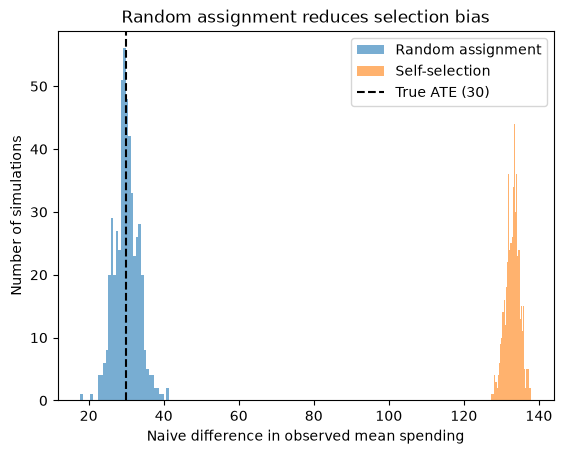

In [8]:
n = 5_000
repetitions = 500
rng = np.random.default_rng(42)

# Create potential outcomes for the same simulated customers.
y0 = rng.lognormal(mean=5.0, sigma=0.6, size=n)  # spending without the program
y1 = y0 + 30                                     # spending with the program
true_ate = (y1 - y0).mean()

# In the self-selected case, higher baseline spenders are more likely to enroll.
z = (y0 - y0.mean()) / y0.std()
p_enroll = 1 / (1 + np.exp(-1.5 * z))

def naive_difference(d):
    observed_y = np.where(d == 1, y1, y0)
    return observed_y[d == 1].mean() - observed_y[d == 0].mean()

# Compare one assignment under each approach.
d_random = rng.binomial(1, 0.5, size=n)  # coin-flip assignment
d_self_selected = rng.binomial(1, p_enroll)

print(f"True ATE: {true_ate:.2f}")
print(f"Naive difference, randomized: {naive_difference(d_random):.2f}")
print(f"Naive difference, self-selected: {naive_difference(d_self_selected):.2f}")

# Repeat assignments to compare the distributions of naive estimates.
random_estimates = []
self_selected_estimates = []

for _ in range(repetitions):
    random_estimates.append(naive_difference(rng.binomial(1, 0.5, size=n)))
    self_selected_estimates.append(naive_difference(rng.binomial(1, p_enroll)))

plt.hist(random_estimates, bins=35, alpha=0.6, label="Random assignment")
plt.hist(self_selected_estimates, bins=35, alpha=0.6, label="Self-selection")
plt.axvline(true_ate, color="black", linestyle="--", label=f"True ATE ({true_ate:.0f})")
plt.xlabel("Naive difference in observed mean spending")
plt.ylabel("Number of simulations")
plt.title("Random assignment reduces selection bias")
plt.legend()
plt.show()

An A/B test works because random assignment makes program participation independent of customers’ pre-existing spending habits, so the treatment and control groups are comparable on average. Their difference in average spending can therefore be attributed to the program rather than selection into it. Randomization doesn’t eliminate chance variation, but larger samples reduce that noise.

---
# Part B: The DAG

## Variables
| Variable | Type | Timing (before/after enrollment) | Observed / latent |
|---|---|---|---|
| enrolled | binary | before | observed |
| spend90 | integer | after | observed |
| welcome_offer | binary | before | observed (randomized) |
| deal_seeking | binary | before | latent |
| income | integer | before | observed |
| store_visits | integer | after | observed |
| store_region | categorical | before | observed |
| survey_responded | binary | after | observed |

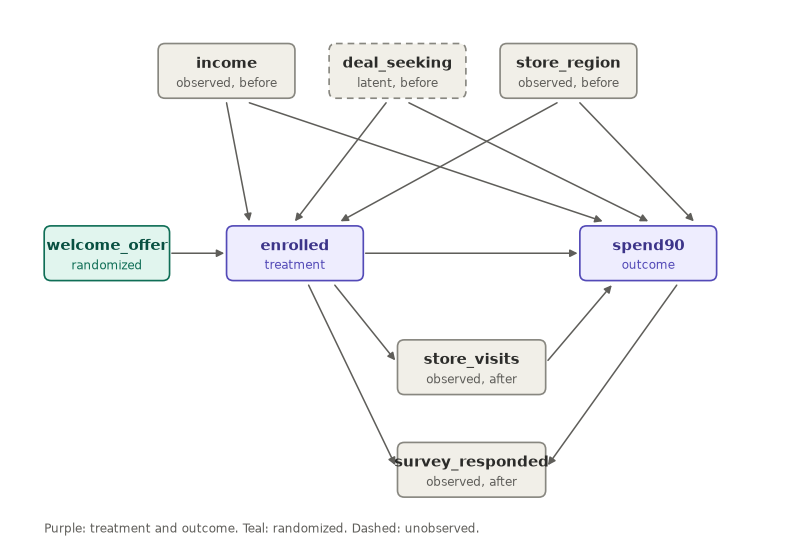

(<Figure size 1000x700 with 1 Axes>, <Axes: >)

In [9]:
draw_reference_dag()

## Arrow justifications

**Randomized offer**
- `welcome_offer -> enrolled`: The randomized offer encourages enrollment but does not itself change the customer’s underlying spending decision.
- `welcome_offer` has no arrow into `spend90` in this DAG, so any effect of the offer on spending is assumed to operate through enrollment.

**Variables that point into both enrollment and spending**
- `income -> enrolled` and `income -> spend90`: Higher-income customers may be more likely to enroll and may also spend more regardless of enrollment.
- `deal_seeking -> enrolled` and `deal_seeking -> spend90`: Price-sensitive customers may seek enrollment and may respond to offers or spend differently.
- `store_region -> enrolled` and `store_region -> spend90`: Store location may be associated with both enrollment access and local spending patterns.

**Effects of enrollment**
- `enrolled -> store_visits`: Enrollment may change how often a customer visits the store.
- `store_visits -> spend90`: Store visits affect the amount spent over the 90-day period.
- `enrolled -> spend90`: This is the direct causal effect of interest.
- `enrolled -> survey_responded` and `spend90 -> survey_responded`: Survey participation may depend on enrollment and spending.

## Arrows I deliberately omitted (and why)
- We omit `income -> store_region` and `store_region -> income` because the project setup does not identify a temporal or causal relationship between them.
- We omit arrows from pre-treatment variables into `welcome_offer` because the offer is randomized, not selected according to customer characteristics.
- We omit `store_visits -> enrolled` because store visits occur after enrollment in the assumed timing; visits may measure downstream use of the program rather than prior enrollment motivation.
- We omit `survey_responded` from the treatment/outcome paths, since survey participation is post-treatment and may be a collider.

In [10]:
# Sanity checks
g = build_dag()
assert nx.is_directed_acyclic_graph(g)
assert g.in_degree("welcome_offer") == 0
assert not g.has_edge("welcome_offer", "spend90")
assert "survey_responded" in g

print("DAG is acyclic:", nx.is_directed_acyclic_graph(g))
print("welcome_offer parents:", list(g.predecessors("welcome_offer")))
print("Direct welcome_offer -> spend90 edge:", g.has_edge("welcome_offer", "spend90"))

DAG is acyclic: True
welcome_offer parents: []
Direct welcome_offer -> spend90 edge: False


---
# Part C: Backdoor reasoning

A backdoor path is a non-causal route between treatment and outcome that starts with an arrow pointing into treatment. It matters because shared causes can make enrollment and spending look related even beyond the program’s actual effect.

In [11]:
paths = backdoor_paths(g, "enrolled", "spend90")
for path in paths:
    arrows = ["->" if g.has_edge(a, b) else "<-" for a, b in zip(path, path[1:])]
    print(" ".join(part for pair in zip(path, arrows) for part in pair) + f" {path[-1]}")

enrolled <- deal_seeking -> spend90
enrolled <- income -> spend90
enrolled <- store_region -> spend90


## My by-hand list of backdoor paths
- `enrolled <- income -> spend90`
- `enrolled <- deal_seeking -> spend90`
- `enrolled <- store_region -> spend90`

**Mismatches with the code output (and why):**
The code should return the same three paths. They each pass through a pre-treatment common cause. `store_visits` is downstream of enrollment, and `survey_responded` is a collider downstream of both enrollment and spending; neither belongs on an open backdoor path in this DAG.

## What is happening on each path?
(For each path: which variable is a confounder, mediator, or collider, if any?)

- `enrolled <- income -> spend90`: `income` is an observed pre-treatment confounder.
- `enrolled <- deal_seeking -> spend90`: `deal_seeking` is a latent pre-treatment confounder.
- `enrolled <- store_region -> spend90`: `store_region` is an observed pre-treatment confounder.
`store_visits` mediates part of the treatment effect. `survey_responded` is a collider because both enrollment and spending cause survey response.

## Adjustment set
**Control for:** `income`, `store_region`, and if measured `deal_seeking`, all of which are pre-treatment confounders in this DAG.

**Must NOT control for (and why):** Do not control for `store_visits` when estimating the total effect, because it is a mediator. Do not control for `survey_responded`, because conditioning on this collider can create bias. `spend90` is the outcome, not a control.

## The deal_seeking question
If `deal_seeking` is unobserved, can I block every backdoor path? What follows for the naive comparison, and for why the randomized offer is valuable?

No, not if `deal_seeking` remains unmeasured: the path `enrolled <- deal_seeking -> spend90` stays open even after adjusting for `income` and `store_region`. The observational enrollment comparison may therefore retain confounding. Because `welcome_offer` is randomized, it can identify the offer’s intention-to-treat effect; estimating the effect of enrollment from the offer requires additional instrumental-variable assumptions, including that the offer has no direct effect on spending.

In [12]:
# Check adjustment in the backdoor graph by removing arrows leaving treatment.
g_backdoor = g.copy()
g_backdoor.remove_edges_from(list(g_backdoor.out_edges("enrolled")))
observed_adjustment = {"income", "store_region"}
full_adjustment = observed_adjustment | {"deal_seeking"}
print("Observed adjustment set blocks all backdoor paths:",
      nx.is_d_separator(g_backdoor, {"enrolled"}, {"spend90"}, observed_adjustment))
print("Including deal_seeking blocks all backdoor paths:",
      nx.is_d_separator(g_backdoor, {"enrolled"}, {"spend90"}, full_adjustment))

Observed adjustment set blocks all backdoor paths: False
Including deal_seeking blocks all backdoor paths: True


---
# Wrap-up

## Key takeaways
1. A raw spending difference mixes the program effect with pre-existing differences between customers who enroll and those who do not.
2. The DAG identifies income, deal-seeking, and store region as confounders; store visits as a mediator; and survey response as a collider.
3. Random assignment balances both measured and unmeasured factors on average, reducing selection bias; estimates can still vary by chance in finite samples.

## Assumptions to log
- Unconfoundedness: After adjustment, no unmeasured pre-treatment factor affects both enrollment and spending; this is questionable if `deal_seeking` is unavailable.
- Overlap: Each relevant customer profile has a positive chance of enrollment and non-enrollment.
- SUTVA: One customer’s enrollment does not affect another customer’s spending, and enrollment is a sufficiently consistent intervention.
- Randomized offer is an invitation, not a discount: It affects spending only through enrollment; if this exclusion assumption fails, the offer is not a valid instrument for enrollment.

## Open questions
- Measure or proxy for latent deal-seeking, and clarify which pre-treatment spending and customer attributes are available.
- Validate the timing and definitions of enrollment, store visits, survey response, and 90-day spending.
- Determine whether the offer affects spending directly and whether enrollment compliance is sufficient for an instrumental-variable analysis.
- Define the target population, follow-up window, and whether effects vary across customer groups.